In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Device selection

In [45]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

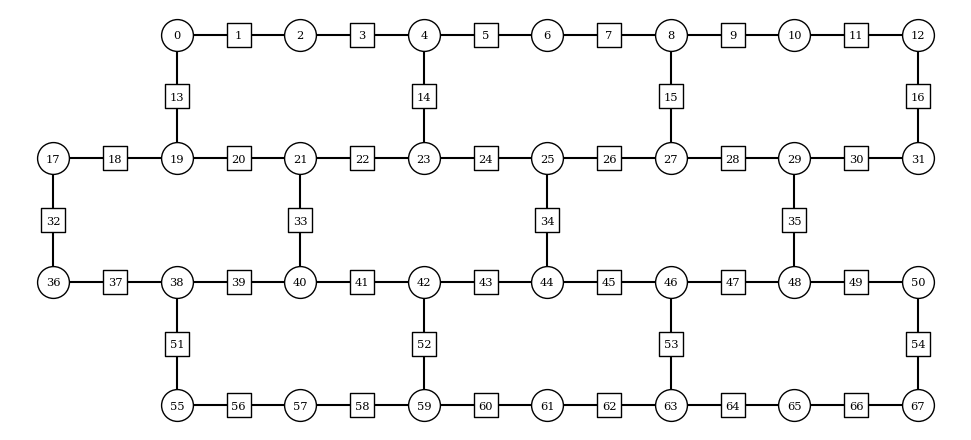

In [46]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

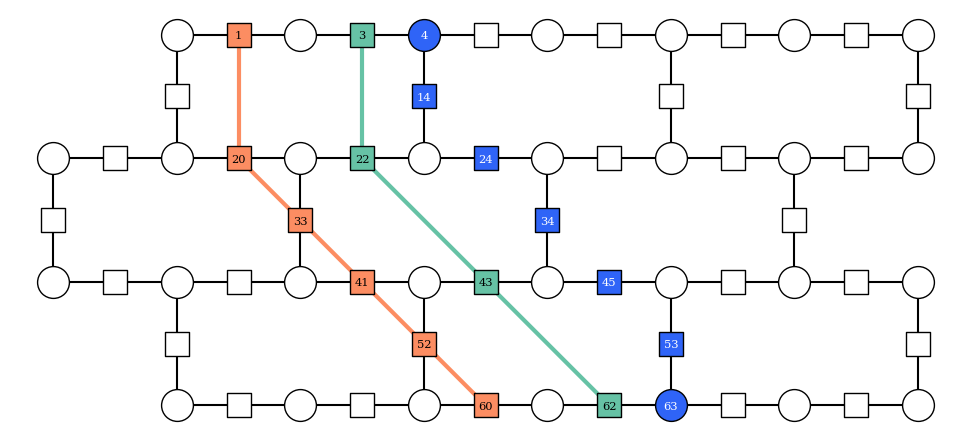

In [47]:
import matplotlib.pyplot as plt

qubits_to_average = [[3, 22, 43, 62], [1, 20, 33, 41, 52, 60]]
string = [4, 14, 24, 34, 45, 53, 63]
cmap = plt.get_cmap("Set2")
qubits_to_highlight = qubits_to_average + [string]
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False])

# Simulation settings

In [48]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB
from utils.execrecord import ExecutionRecord

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 0.01
lamb = 1
g = 10

x_basis = False

fractional_gates = False

# strings_arr = [[6, 7, 8, 16, 26, 25, 24, 34, 43, 44, 45, 54, 64, 63, 62, 72, 81, 82, 83, 92, 102, 101, 100]]
string = [4, 14, 24, 34, 45, 53, 63]
# strings_arr = [[12, 16, 30, 35, 47, 53, 64, 72, 81, 90, 98, 109, 115, 127, 131]]
# strings_arr = [[4, 14, 24]]

final_time = 5
dt = 0.2
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 75000

odr = True
flip_threshold = None
all_or_first_layout_qubit = 43
forbidden_qubits = []
max_layouts = 4

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection_old.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

# Error guarantees

In [49]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

With provided the hardware error Δt should be:
Δt = 0.02560
To correctly reach the desired final time, the number of layers required is:
N = 196 (1176 2Qb depth)


In [50]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice,J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.20000
The error per layer commited in the wrost case is
Ɛ = 4.7667
The number of layers at the final evolution time is
N = 24 (144 2Qb depth)


# Circuit generation & observables

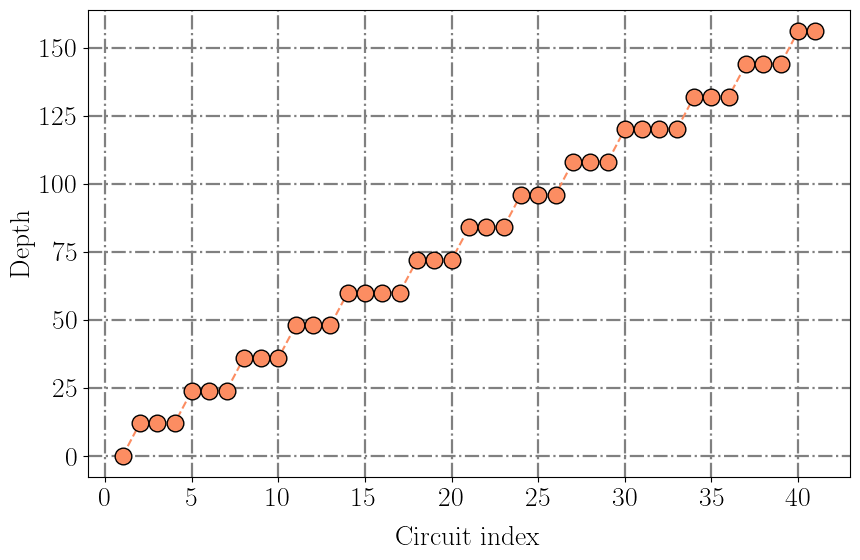

In [51]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]
circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g, layouts, x_basis, True, False)
# if os.path.exists(circuits_filepath):
#     circuits = load_many_layout_circs(circuits_filepath)
# else:
#     circuits = string_quench_simulation_circuits_dt(*circs_args)
    # save_many_layout_circs(circuits_filepath, circuits)
circuits = string_quench_simulation_circuits_dt(*circs_args)
# extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_circuits_filepath = os.path.join(circ_folder_path, f"z2hex_odr_compuncomp_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
    odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string, layouts, x_basis)
    if os.path.exists(odr_circuits_filepath):
        odr_circuits = load_many_layout_circs(odr_circuits_filepath)
    else:
        odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
        if os.path.isdir(os.path.dirname(circuits_filepath)):
            save_many_layout_circs(odr_circuits_filepath, odr_circuits)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

plot_circuit_arr_depth(circuits[0])

# Load jobs with the same options

In [9]:
from utils.postselection import load_postselected_jobs

if odr:
    observables, observables_std, samples_dicts, postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_std=True, return_samples_dicts=True, return_postselected_samples_dicts=True)
else:
    observables, observables_std, samples_dicts, postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_std=True, return_samples_dicts=True, return_postselected_samples_dicts=True)

# Plots

## Single frame plots

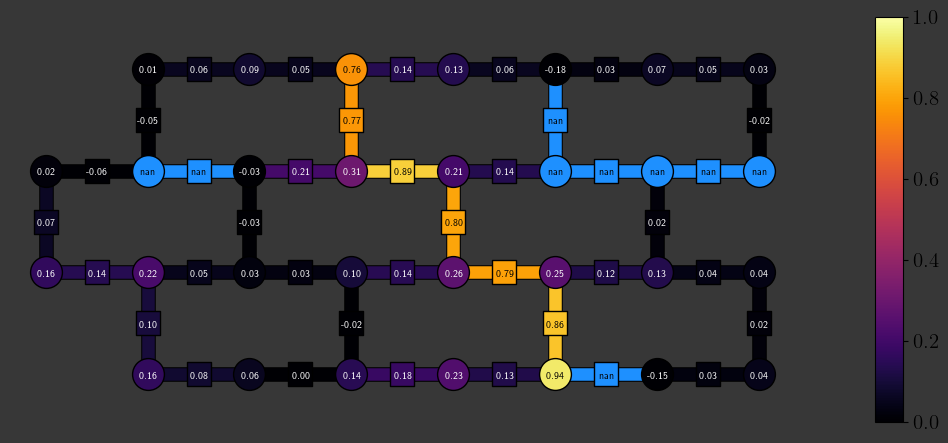

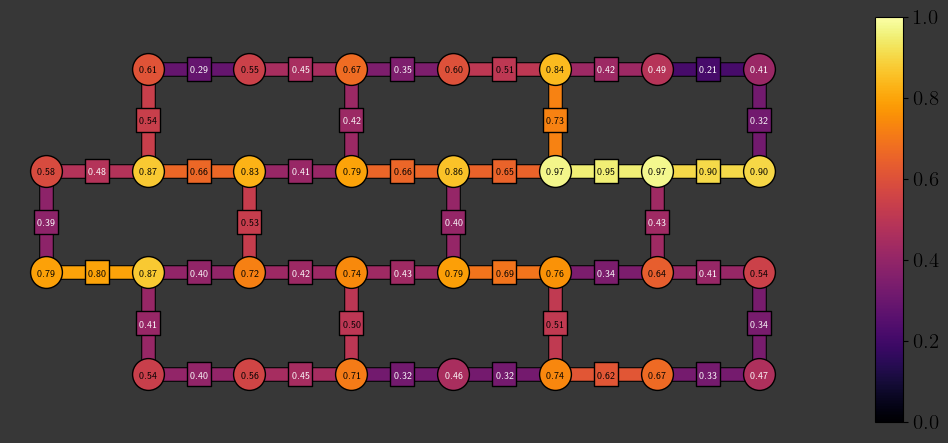

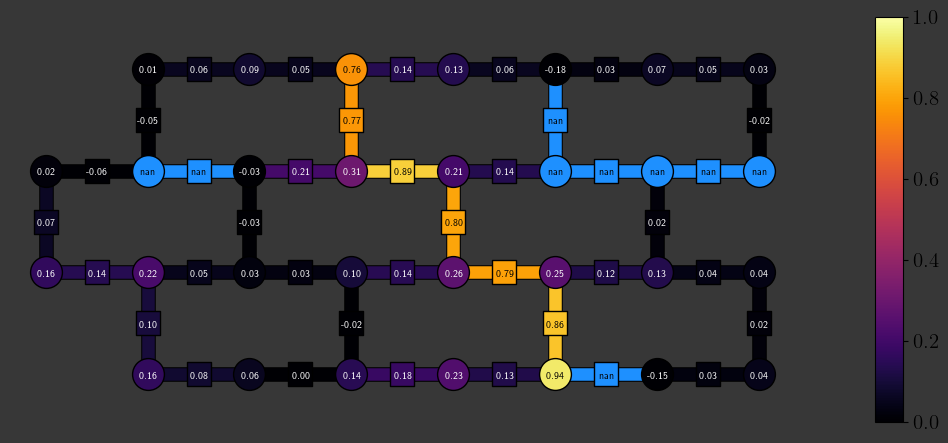

In [18]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot
import utils.odr as odr

job_index = 20

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

psamples = postselected_samples_dicts[0][0][job_index]
podrsamples = postselected_samples_dicts[1][0][job_index]
pobservables = measure_diagonal_observables(podrsamples, diagonal_observables, circuits[0][job_index].layout.final_index_layout())[::-1]
podrprob = odr.compute_depolarizing_probability(pobservables, 1, 0, odr_circuits[0][job_index].num_qubits)
finalobs = odr.renormalize_observable(observables[1][job_index], podrprob, 0, circuits[0][job_index].num_qubits, [-1, 1])

local_observable_plot((1-observables[0][job_index])/2, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot(podrprob, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot((1-finalobs)/2, lattice, cmap_range=[0, 1], dark_theme=True)

## Animation

In [ ]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

postselected_odr_filepath = f"2D plots/z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"2D plots/z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
odr_filepath = f"2D plots/z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
raw_filepath = f"2D plots/z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
local_obs_anim((1-observables[0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
local_obs_anim((1-observables[1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
local_obs_anim((1-observables[2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
local_obs_anim((1-observables[3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

## Single qubit plots

### Matter qubits near to the string ends

#### Top end (Transversal)

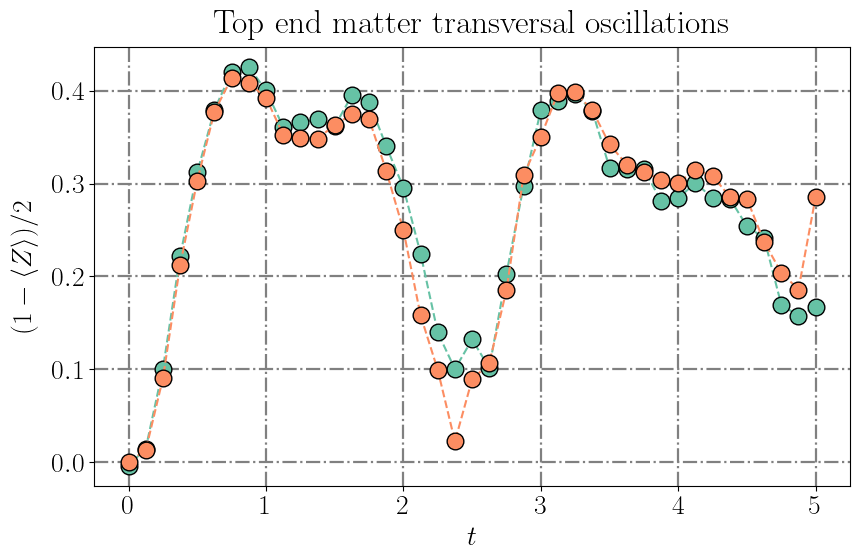

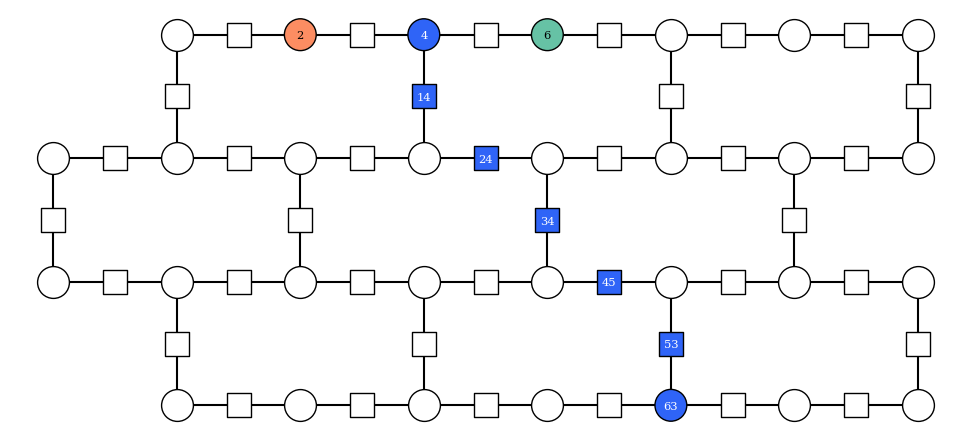

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Top end matter transversal oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 1), (0, -1)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_std = observables_std[0][:, to_plot_qubit_inds]
plot_filepath = f"z2hex_quench_top_end_transversal_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_transversal_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, None, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + string, colors=[cmap(0), cmap(1)]+["#2f64f7"]*len(string), filepath=legend_filepath)

#### Top end (longitudinal)

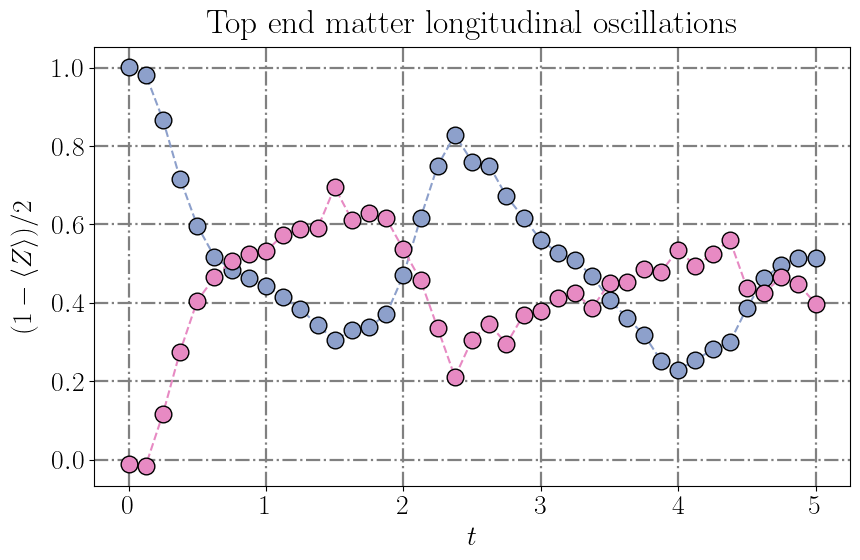

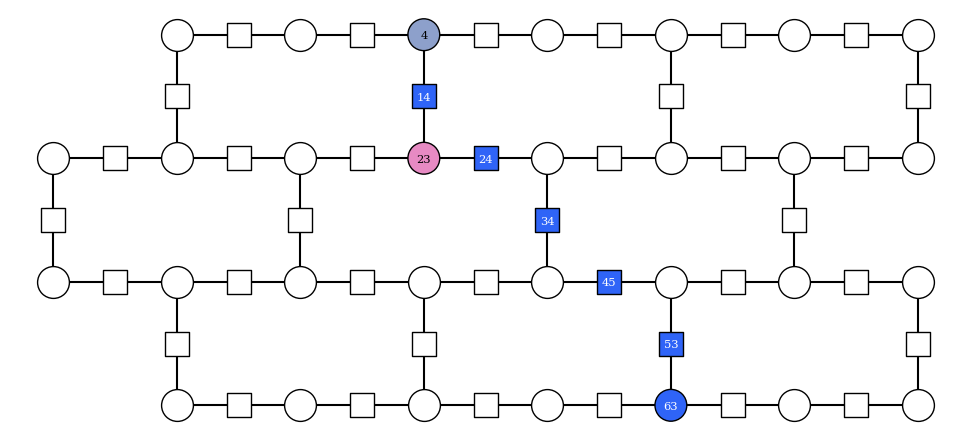

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Top end matter longitudinal oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = [string_qubit_coords[0]]

for axisdir in [(1, 0), (-1, 0)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)
        
to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_std = observables_std[0][:, to_plot_qubit_inds]
plot_filepath = f"z2hex_quench_top_end_longitudinal_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_logitudinal_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, None, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
string_qb_highlighted = [qb for qb in string if qb not in to_plot_qubit_inds]
lattice.plot_highlighted_qubits(to_plot_qubit_inds + [qb for qb in string if qb not in to_plot_qubit_inds], colors=[cmap(0), cmap(1)]+["#2f64f7"]*len(string_qb_highlighted), filepath=legend_filepath)

#### Bottom end (Transversal)

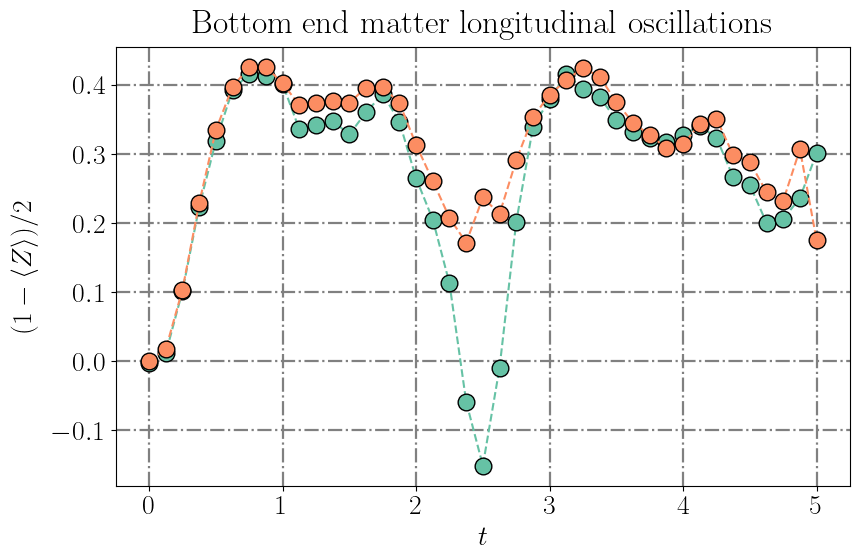

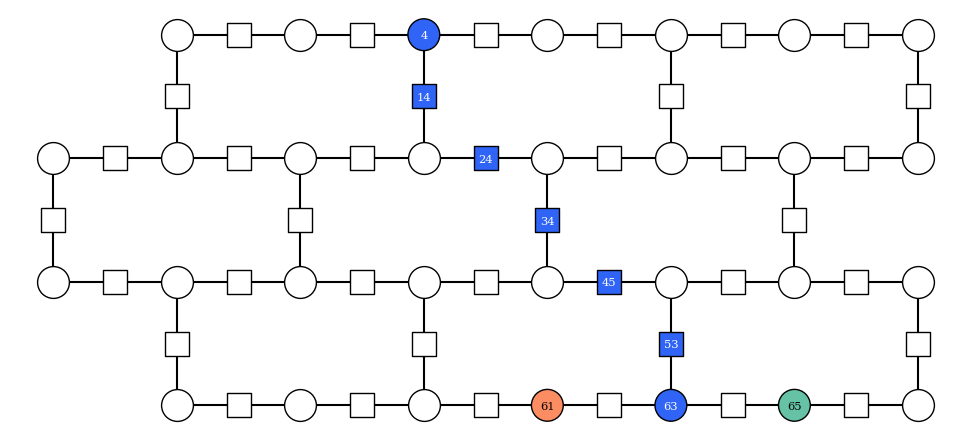

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Bottom end matter longitudinal oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 1), (0, -1)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)
        
to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_std = observables_std[0][:, to_plot_qubit_inds]
plot_filepath = f"z2hex_quench_bottom_end_transversal_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_transversal_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, None, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + string, colors=[cmap(0), cmap(1)]+["#2f64f7"]*len(string), filepath=legend_filepath)

#### Bottom end (Logitudinal)

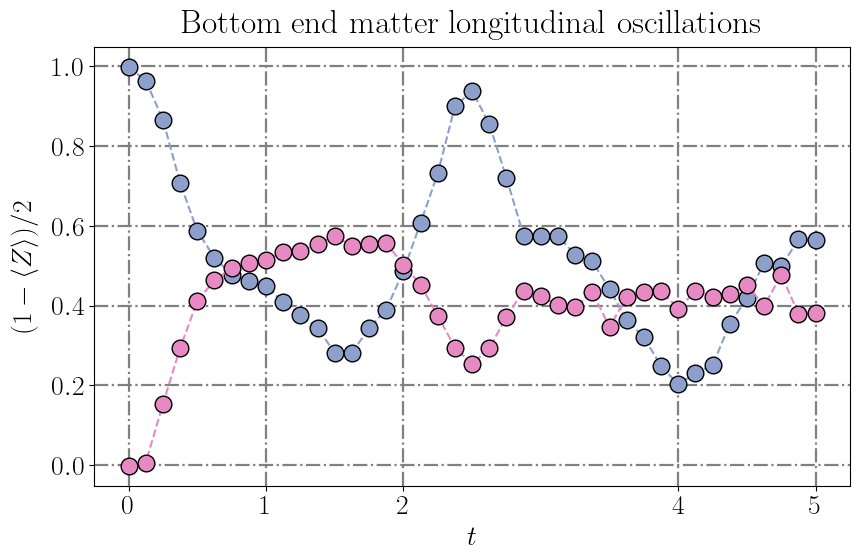

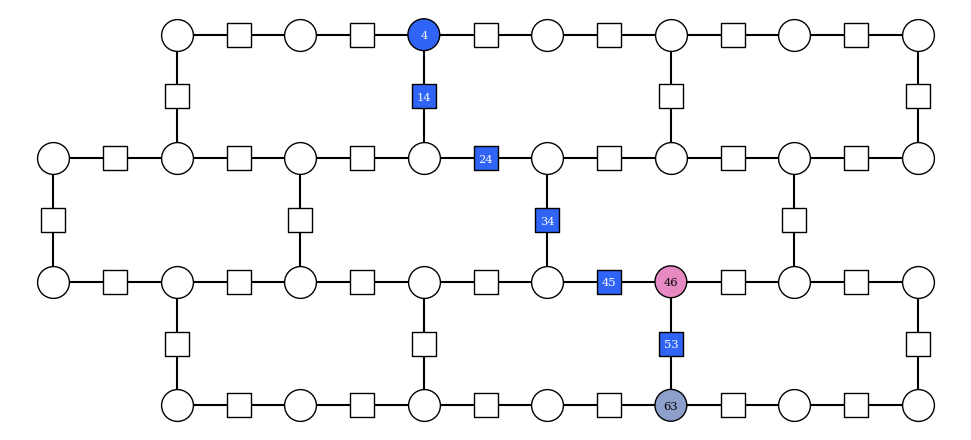

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Bottom end matter longitudinal oscillations"

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = [string_qubit_coords[-1]]

for axisdir in [(1, 0), (-1, 0)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)
        
to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_std = observables_std[0][:, to_plot_qubit_inds]
plot_filepath = f"z2hex_quench_bottom_end_longitudinal_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_longitudinal_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 5)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, None, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + [qb for qb in string if qb not in to_plot_qubit_inds], colors=[cmap(0), cmap(1)]+["#2f64f7"]*len(string_qb_highlighted), filepath=legend_filepath)

## String plots

#### Left gauge covering plots

/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/plotting.py:341: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "--o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(x, average_observable_matrix[:, i], "--o", marker=markers[i] if markers is not None else "o", markersize=12, markeredgecolor="black", color=color, label="Average")


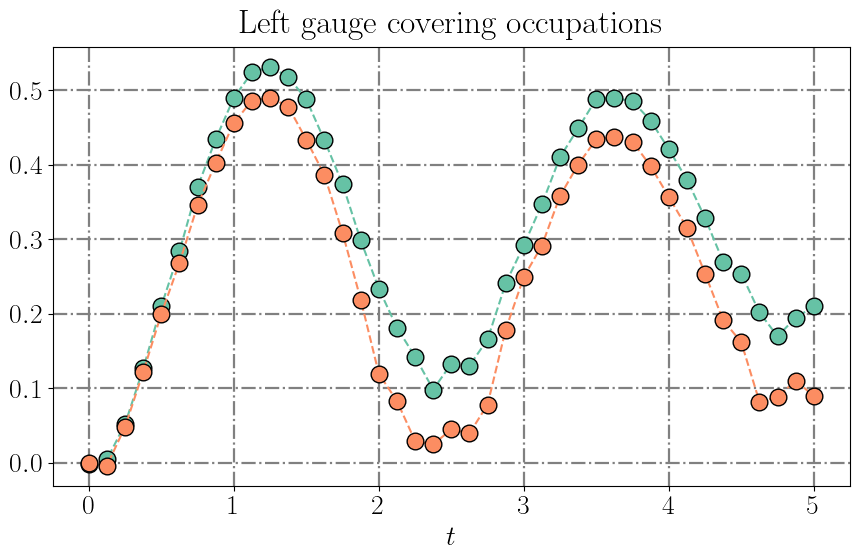

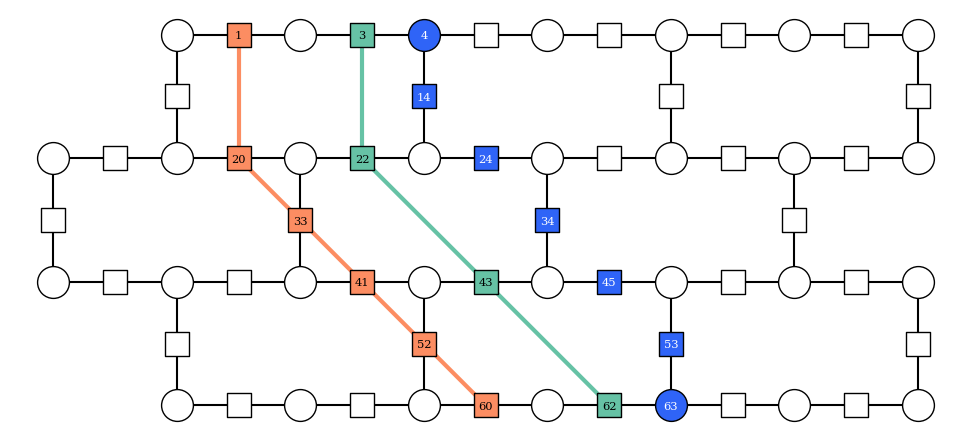

In [39]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Left gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement + 1)
            candidates = [(matter_reference[0] - 0.5, matter_reference[1]), (matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, markers=markers, x_ticks=x_ticks, x_label=r"$t$", title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right gauge covering plots

/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/plotting.py:341: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "--o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(x, average_observable_matrix[:, i], "--o", marker=markers[i] if markers is not None else "o", markersize=12, markeredgecolor="black", color=color, label="Average")


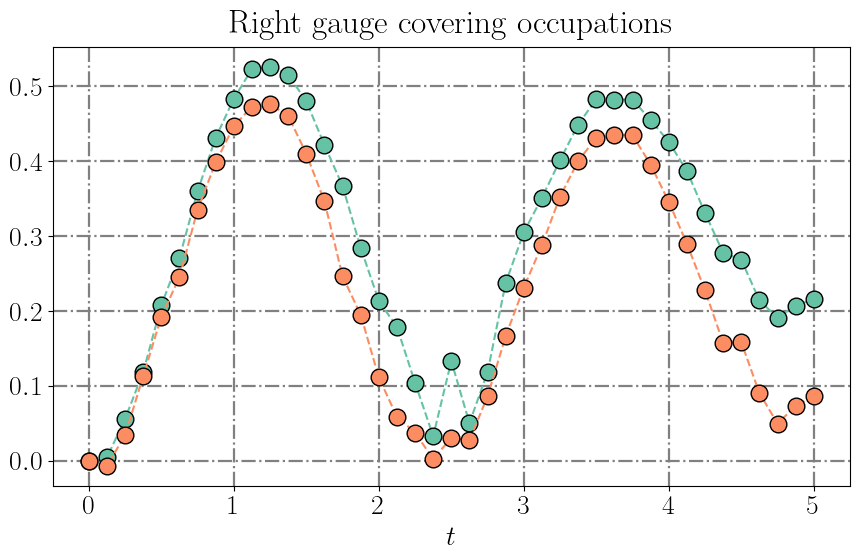

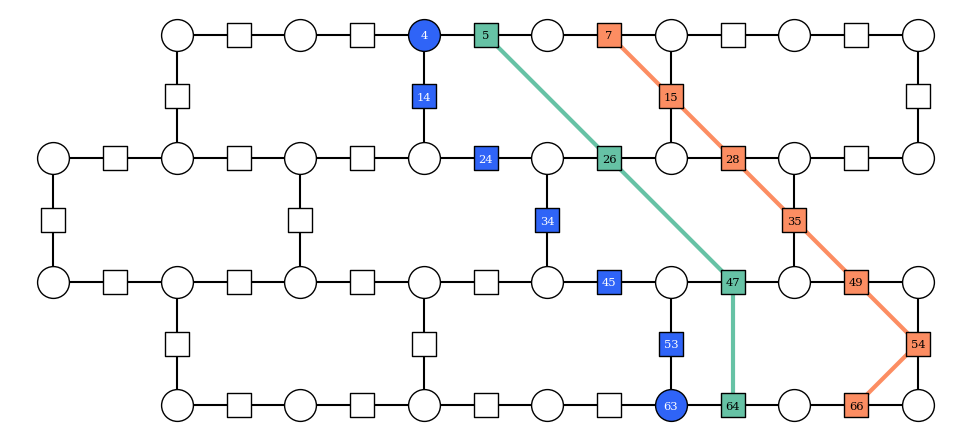

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Right gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            candidates = [(matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, markers=markers, x_ticks=x_ticks, x_label=r"$t$", title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Left matter covering plots

/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/plotting.py:341: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "--o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(x, average_observable_matrix[:, i], "--o", marker=markers[i] if markers is not None else "o", markersize=12, markeredgecolor="black", color=color, label="Average")


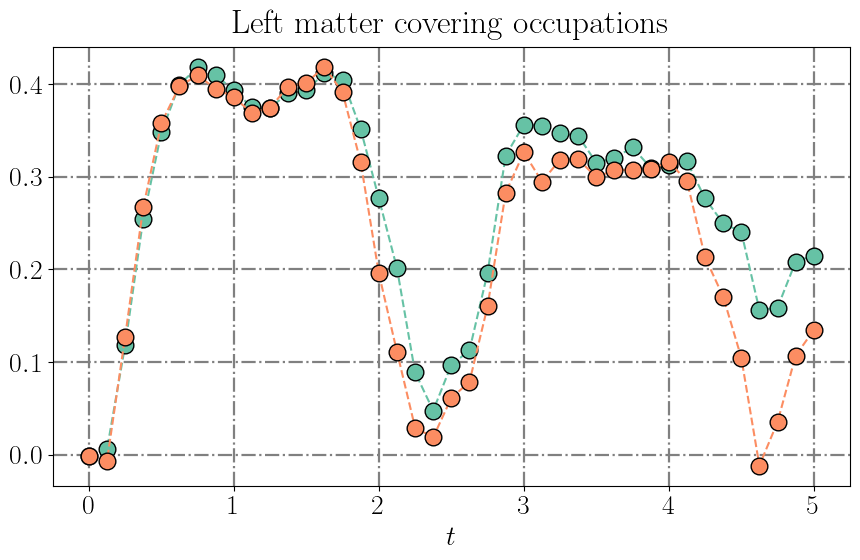

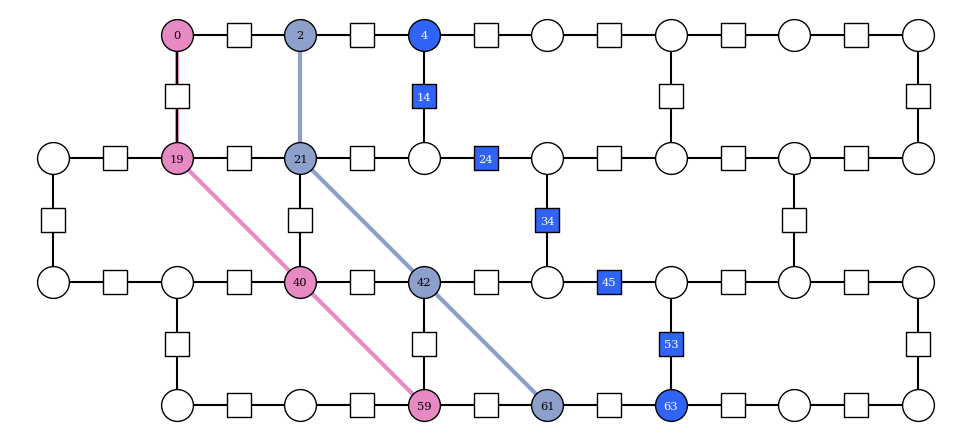

In [42]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Left matter covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if candidate in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, markers=markers, x_ticks=x_ticks, x_label=r"$t$", title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right matter covering plots

/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/plotting.py:341: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "--o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(x, average_observable_matrix[:, i], "--o", marker=markers[i] if markers is not None else "o", markersize=12, markeredgecolor="black", color=color, label="Average")


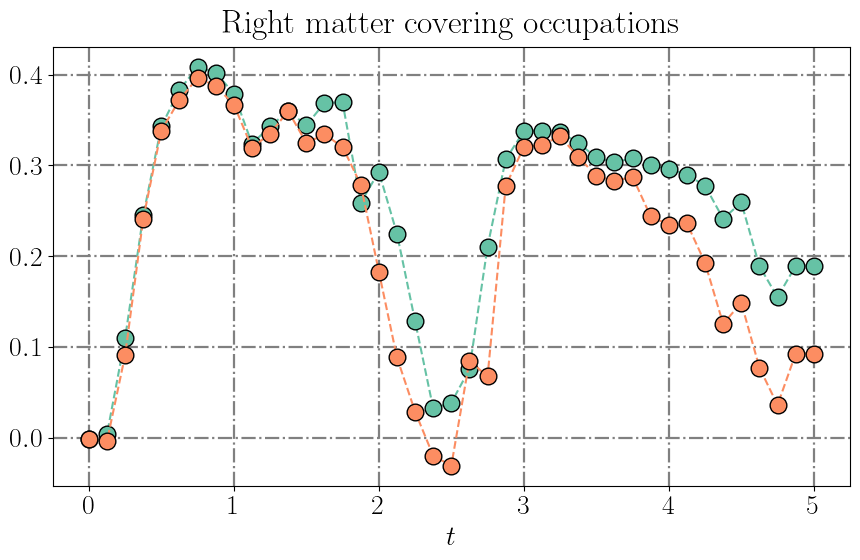

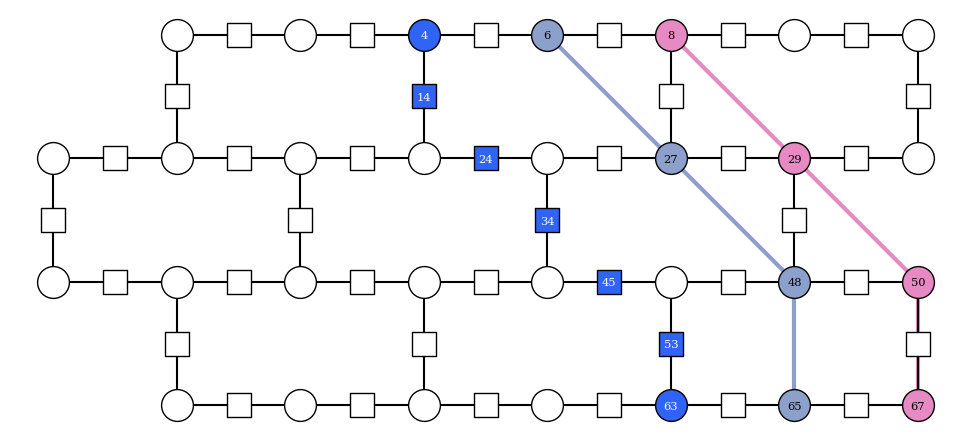

In [43]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Right matter covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, markers=markers, x_ticks=x_ticks, x_label=r"$t$", title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

# Record tools

## Add separator

In [18]:
# execrecord.add_separator()